# Pass 05

## Problem Definition


Business problem: estimate a house’s sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import Ridge #ridge regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load data
house_df= pd.read_csv(url,
               usecols= ['Lot Frontage','SalePrice'])





In [4]:
# look at first and last few rows
print(house_df.head())
print(house_df.tail())

   Lot Frontage  SalePrice
0          62.0     115400
1          72.0      90000
2          50.0     141000
3          68.0     254000
4          60.0     155000
      Lot Frontage  SalePrice
2632          52.0     114500
2633          74.0     162000
2634          61.0     211500
2635          78.0     165000
2636          41.0     225000


In [5]:
# look at shape and size

print(house_df.shape)
print(house_df.size)


(2637, 2)
5274


In [6]:
# display meta data (info)
house_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Lot Frontage  2188 non-null   float64
 1   SalePrice     2637 non-null   int64  
dtypes: float64(1), int64(1)
memory usage: 41.3 KB


In [7]:
# display summary statistics
house_df.describe()



,Lot Frontage,SalePrice
count,2188.000000,2637.000000
mean,69.166819,179986.230186
std,23.356779,78309.251522
min,21.000000,12789.000000
25%,58.000000,129500.000000
50%,68.000000,160000.000000
75%,80.000000,213000.000000
max,313.000000,745000.000000


In [8]:
# Columns data types
house_df.dtypes.sort_values()


,0
SalePrice,int64
Lot Frontage,float64


In [9]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [10]:
# look for nulls in target and features
house_df.isnull().sum().sort_values(ascending=False)

,0
Lot Frontage,449
SalePrice,0


In [11]:
# look for nulls in feature in percentage
house_df['Lot Frontage'].isnull().mean() * 100

np.float64(17.02692453545696)

## Data Cleaning


### Backup 1

In [12]:
# make backup
house_df_backup= house_df.copy()

In [13]:
# restore from backup
house_df = house_df_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

### Impute

In [14]:
# Calculate the median
median_frontage = house_df['Lot Frontage'].median()
print(median_frontage)

# Fill nulls with the median
house_df['Lot Frontage']= house_df['Lot Frontage'].fillna(median_frontage)

#verify there are no nulls
house_df.isnull().sum()


68.0


,0
Lot Frontage,0
SalePrice,0


In [15]:
house_df['Lot Frontage'].median()

68.0

## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

In [16]:
# Calculate a correlation matrix for target
house_df.corr() ;

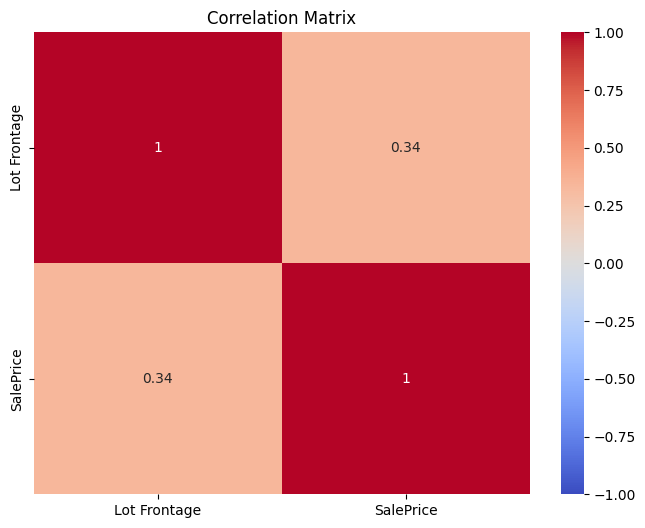

In [17]:
# Display the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(house_df.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()

## Processing



### Fit & Assess our model

#### Using Ridge Regression

In [18]:
# break data into training and testing sets
X = house_df[['Lot Frontage']]
y = house_df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

In [19]:
# Fit a Ridge model using sklearn
model = Ridge(alpha=1)      # alpha = penalty strength (1 is the default)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

(model.intercept_, model.coef_)

(np.float64(92494.05185390603), array([1260.58992935]))

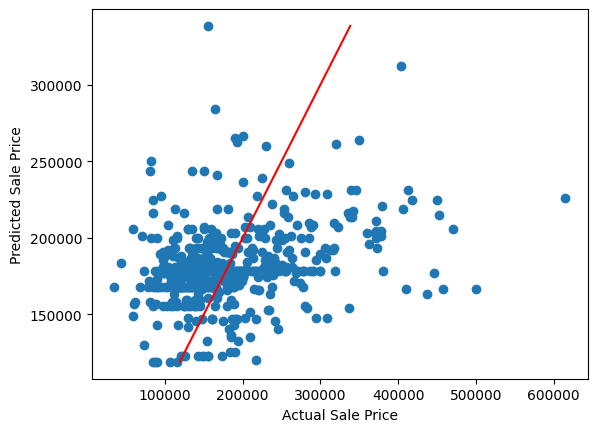

In [20]:
# See how well the model does compared to the test data
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)], [min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price');

In [21]:
# RMSE on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse}")

RMSE: 75252.77251406597


In [25]:
# Use cross validation to assess model performance
results = cross_val_score(model, X, y, scoring='neg_root_mean_squared_error', cv=10)
cv_rmse = abs(results.mean())
print(f"CV RMSE: {cv_rmse}")

CV RMSE: 73679.3305643495


### Residual Analysis

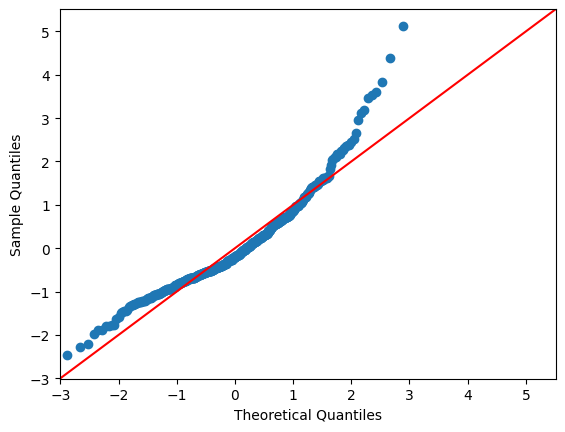

In [22]:
# QQ Plot -checks if residuals (misses) are normally distributed (bell-shaped)
res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

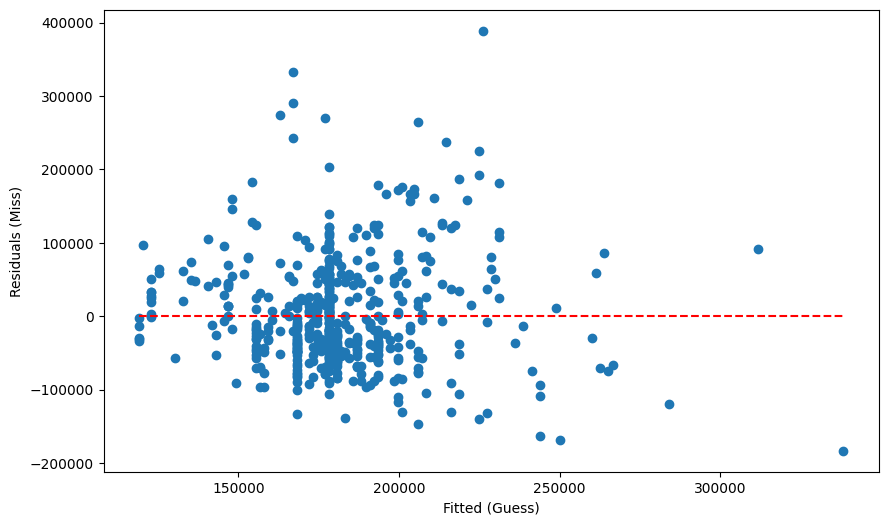

In [23]:
# Residuals vs Fitted (Predicted) Values - Constant variance

plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted (Guess)")
plt.ylabel("Residuals (Miss)")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

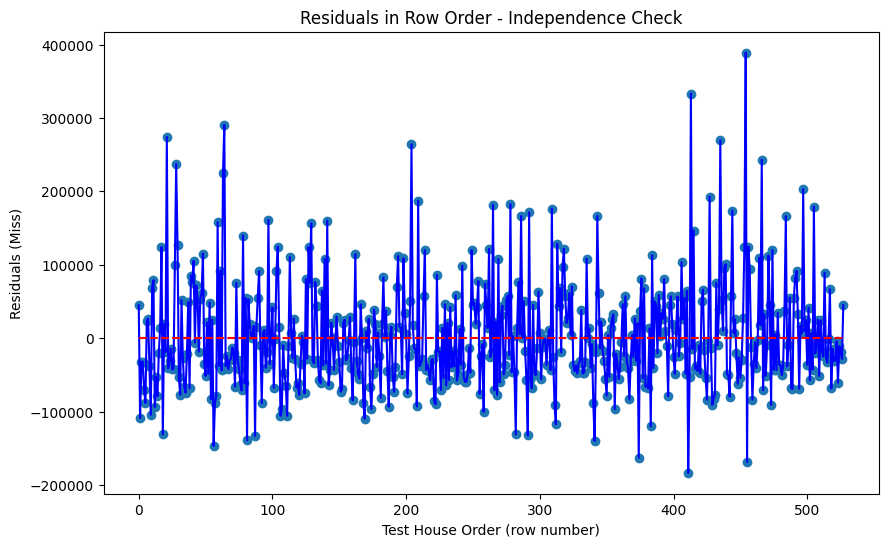

In [24]:
# Residuals in Row Order - checks independence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Test House Order (row number)")
plt.ylabel("Residuals (Miss)")
plt.title("Residuals in Row Order - Independence Check")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

## Communication of Results


**Model:** Ridge Regression, one feature (Lot Frontage)

**Scores:**
- RMSE: $75,253
- CV RMSE: $73,679
- Same as Linear Regression in Pass 4.

**Residuals:**
- QQ plot: skewed right. Expensive houses are guessed too low.
- Fitted plot: no funnel, so roughly OK.
- Row order: random, OK.

**Conclusion:**
Ridge did not improve the model. With one feature, Ridge and Linear give the same answer. Lot frontage alone is a weak predictor. More features are needed.